# Experiment 7: Dimensionality Reduction with Principal Component Analysis (PCA)

---
### **Aim / Objective:**
To apply Principal Component Analysis (PCA) to reduce high-dimensional data, analyze explained variance ratios, and visualize clusters in a 2D projection space.

---
### **Theory & Overview:**
Principal Component Analysis (PCA) is an orthogonal linear transformation technique:
1. Standardizes data to zero mean and unit variance.
2. Computes the Covariance Matrix $\mathbf{\Sigma} = \frac{1}{n-1} \mathbf{X}^T \mathbf{X}$.
3. Solves for Eigenvectors (principal axes) and Eigenvalues (magnitude of variance explained).
4. Projects high-dimensional data onto the top $k$ principal components, retaining maximum information with minimum dimensional footprint.



### **1. Loading High-Dimensional Digits Dataset**


In [ ]:
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np

digits = load_digits()
X = digits.data
y = digits.target

print(f"Original dataset shape: {X.shape} (64 pixel features per sample)")
print(f"Target classes (digits 0-9): {np.unique(y)}")

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



Original dataset shape: (1797, 64) (64 pixel features per sample)
Target classes (digits 0-9): [0 1 2 3 4 5 6 7 8 9]


### **2. Applying PCA & Calculating Explained Variance**


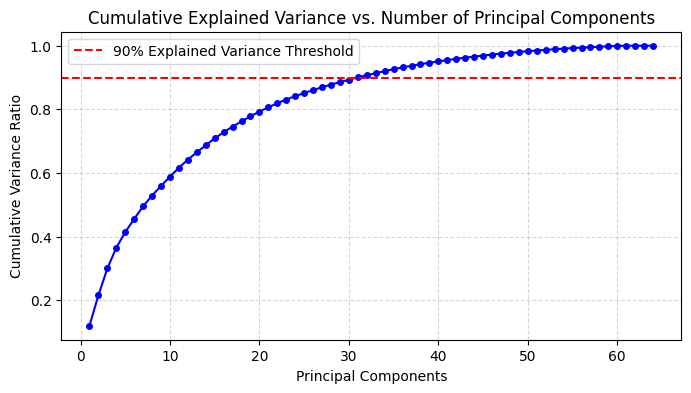

Number of components needed to retain >= 90% variance: 31 out of 64


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Fit full PCA to inspect cumulative variance
pca_full = PCA()
pca_full.fit(X_scaled)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, 'b-o', markersize=4)
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Explained Variance Threshold')
plt.title("Cumulative Explained Variance vs. Number of Principal Components")
plt.xlabel("Principal Components")
plt.ylabel("Cumulative Variance Ratio")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

n_90 = np.argmax(cum_var >= 0.90) + 1
print(f"Number of components needed to retain >= 90% variance: {n_90} out of 64")



### **3. 2D PCA Transformation and Visualization**


Variance explained by PC1: 12.03%
Variance explained by PC2: 9.56%


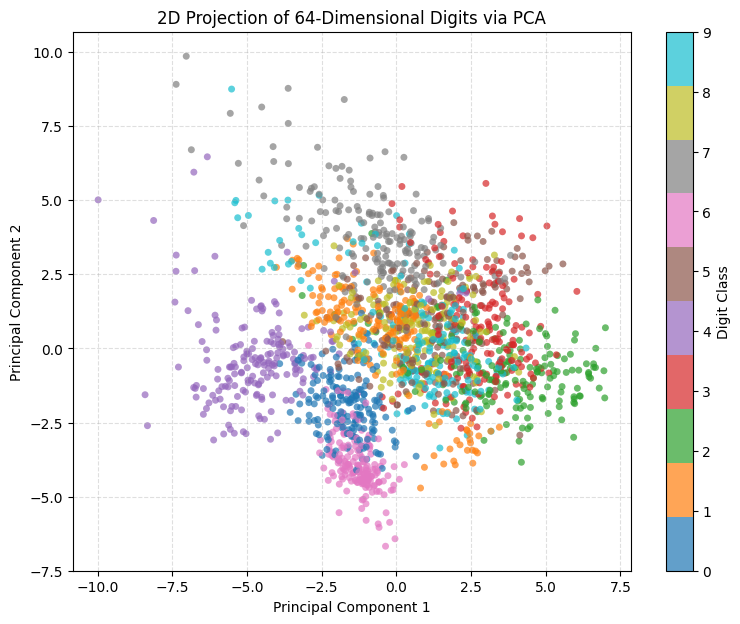

In [ ]:
# Fit 2-Component PCA for 2D visualization
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

print(f"Variance explained by PC1: {pca_2d.explained_variance_ratio_[0]*100:.2f}%")
print(f"Variance explained by PC2: {pca_2d.explained_variance_ratio_[1]*100:.2f}%")

plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='tab10', alpha=0.7, edgecolors='none', s=25)
plt.colorbar(scatter, label='Digit Class')
plt.title("2D Projection of 64-Dimensional Digits via PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()



---
### **Conclusion & Learning Outcomes:**
Successfully reduced 64-dimensional pixel data down to 2 principal components while retaining dominant variance structures, demonstrating PCA's power in data compression and visual exploration.
